# CNN Practice for Timeseries
Heavily inspired by Mayur Ingole, https://medium.com/@myringoleMLGOD/simple-convolutional-neural-network-cnn-for-dummies-in-pytorch-a-step-by-step-guide-6f4109f6df80

In [ ]:
# Use vnv timeseries_cnn_test with Python 3.13.9

import torch
import numpy as np
from torch.utils.data import Dataset
from torch.utils.data import DataLoader
from torchvision import datasets
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

import torch.nn.functional as F
import torchvision.datasets as datasets
from torch import optim
from torch import nn
import pandas as pd
from pathlib import Path
from sklearn.model_selection import train_test_split
from tqdm import tqdm


In [3]:

def imshow(sample_element, shape = (28, 28)):
    plt.imshow(sample_element[0].numpy().reshape(shape), cmap='gray')
    plt.title('Label = ' + str(sample_element[1]))
    plt.show()

In [345]:
# OLD CNN USED FOR SINGLE LABEL CLASSIFICATION
class old_CNN(nn.Module):
    def __init__(self, in_channels, num_classes=10):
        """
        Define the layers of the convolutional neural network.

        Parameters:
            in_channels: int
                The number of channels in the input image. For MNIST, this is 1 (grayscale images).
            num_classes: int
                The number of classes we want to predict, in our case 10 (digits 0 to 9).
        """
        super(CNN, self).__init__()

        # First convolutional layer: 1 input channel, 8 output channels, 3x3 kernel, stride 1, padding 1
        self.conv1 = nn.Conv1d(in_channels=in_channels, out_channels=8, kernel_size=3, stride=1, padding=1)
        # Max pooling layer: 2x2 window, stride 2
        self.pool = nn.MaxPool1d(kernel_size=2, stride=2)
        # Second convolutional layer: 8 input channels, 16 output channels, 3x3 kernel, stride 1, padding 1
        self.conv2 = nn.Conv1d(in_channels=8, out_channels=16, kernel_size=3, stride=1, padding=1)
        # Fully connected layer: 16*7*7 input features (after two 2x2 poolings), 10 output features (num_classes)
        self.fc1 = nn.LazyLinear(num_classes)

    def forward(self, x):
        """
        Define the forward pass of the neural network.

        Parameters:
            x: torch.Tensor
                The input tensor.

        Returns:
            torch.Tensor
                The output tensor after passing through the network.
        """
        x = F.relu(self.conv1(x))  # Apply first convolution and ReLU activation
        x = self.pool(x)           # Apply max pooling
        x = F.relu(self.conv2(x))  # Apply second convolution and ReLU activation
        x = self.pool(x)           # Apply max pooling
        x = x.reshape(x.shape[0], -1)  # Flatten the tensor
        x = self.fc1(x)            # Apply fully connected layer
        return x

In [14]:
# New CNN used for multiple label classification
class CNN(nn.Module):
    def __init__(self, in_channels, task_classes):
        """
        Parameters:
            in_channels: int
                Number of signal channels per window (1 for ECG only, 2 for ECG + GSR).
            task_classes: dict[str, int]
                One entry per label to predict, mapping its name to its number of classes,
                e.g. {"Valence level": 10, "Arousal level": 10}.
        """
        super().__init__()
        self.tasks = list(task_classes)

        # Shared feature extractor, used by every label
        self.conv1 = nn.Conv1d(in_channels, 8, kernel_size=3, stride=1, padding=1)
        self.conv2 = nn.Conv1d(8, 16, kernel_size=3, stride=1, padding=1)
        self.pool = nn.MaxPool1d(kernel_size=2, stride=2)

        # One output layer per label
        self.heads = nn.ModuleDict({
            name: nn.LazyLinear(n) for name, n in task_classes.items()
        })

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = x.flatten(1)
        return {name: head(x) for name, head in self.heads.items()}

In [7]:
### Hyperparameters ###

input_size = 784  # 28x28 pixels (not directly used in CNN)
num_classes = 11  # digits 0-10
learning_rate = 0.001
batch_size = 64
num_epochs = 20  # Reduced for demonstration purposes

In [26]:
### Pre-Process the Data ### 


fs = 128.0 # DATA RECORDED AT 128HZ for GSR and ECG as well.



# Load self-reported annotations
annotations_file = "/Users/Ben/Desktop/ECG_GSR_Emotions/Self-Annotation Labels/Self-annotation Multimodal_Use.xlsx"
annotations = pd.read_excel(annotations_file)
#print(annotations.head)

all_samples = pd.DataFrame({})

# TODO: Turn into a for loop
path = "/Users/Ben/Desktop/ECG_GSR_Emotions/Raw Data/Multimodal/ECG/"
path2 = "/Users/Ben/Desktop/ECG_GSR_Emotions/Raw Data/Multimodal/GSR/"
files = [p for p in Path(path).iterdir() if p.is_file()]
batches = []
for file in files:
    ecg_x = np.loadtxt(str(file), delimiter=",")   # add delimiter="," for commas, skiprows=1 for a header
    gsr_x = np.loadtxt(str(path2 + "GSR" + file.name[3:]))
    #print(x.shape)

    t = np.arange(len(ecg_x)) / fs

    window_size = 15.0 # In seconds
    num_elems_in_window = int(window_size * (fs / 60.0))

    # Take the raw ECG values and split into windows
    windows = np.lib.stride_tricks.sliding_window_view(ecg_x, num_elems_in_window)
    gsr_windows = np.lib.stride_tricks.sliding_window_view(gsr_x, num_elems_in_window)
    #print(num_elems_in_window)

    # Look up the annotations for each file
    def parse_spv(path):
        path = path.lower()
        m = re.search(r"s(\d+)p(\d+)v(\d+)$", Path(path).stem)
        if not m:
            raise ValueError(f"No s/p/v pattern at the end of {path}")
        return tuple(int(g) for g in m.groups())

    s, p, v = parse_spv(str(file))

    row = annotations[(annotations["Participant Id"] == s) & (annotations["Session ID"] == p) & (annotations["Video ID"] == v)]
    if len(row) > 1:
        #print(row)
        row = row.head(1)
        #print(row)
        # TODO: Understand why there are almost duplicates in the annotation xlsx
    if len(row) == 0:
        continue
    row = row.drop(columns=["Name", "Age", "Gender"])

    # inside your per-file loop, in place of the window loop:
    batch = row.loc[row.index.repeat(len(windows))].reset_index(drop=True)
    batch.insert(0, "window_sample", list(windows))
    #batch = row.loc[row.index.repeat(len(windows))].reset_index(drop=True)
    batch.insert(0, "gsr_window_sample", list(gsr_windows))
    #print(batch)
    batches.append(batch)

# after the per-file loop has finished:
all_samples = pd.concat(batches, ignore_index=True)

print(all_samples)

                                        gsr_window_sample  \
0       [246.32, 246.41, 246.59, 246.52, 246.58, 246.8...   
1       [246.41, 246.59, 246.52, 246.58, 246.87, 247.0...   
2       [246.59, 246.52, 246.58, 246.87, 247.04, 247.0...   
3       [246.52, 246.58, 246.87, 247.04, 247.06, 247.1...   
4       [246.58, 246.87, 247.04, 247.06, 247.13, 247.3...   
...                                                   ...   
298135  [412.84, 413.02, 412.86, 412.76, 412.84, 413.0...   
298136  [413.02, 412.86, 412.76, 412.84, 413.02, 412.8...   
298137  [412.86, 412.76, 412.84, 413.02, 412.86, 413.0...   
298138  [412.76, 412.84, 413.02, 412.86, 413.0, 412.88...   
298139  [412.84, 413.02, 412.86, 413.0, 412.88, 412.98...   

                                            window_sample  Participant Id  \
0       [-5.8012, -5.8034, -5.8438, -5.8428, -5.8271, ...               1   
1       [-5.8034, -5.8438, -5.8428, -5.8271, -5.8433, ...               1   
2       [-5.8438, -5.8428, -5.8271, 

In [37]:
class WindowDataset(Dataset):
    def __init__(self, df, label_cols):
        df = df.reset_index(drop=True)
        ecg = np.stack(df["window_sample"].to_numpy())
        gsr = np.stack(df["gsr_window_sample"].to_numpy())
        self.X = torch.tensor(np.stack([ecg, gsr], axis=1), dtype=torch.float32)
        self.y = torch.tensor(df[label_cols].to_numpy(), dtype=torch.long)  # labels must start at 0

    def __len__(self):
        return len(self.y)

    def __getitem__(self, i):
        return self.X[i], self.y[i]

In [28]:
### Data Pre-Process and Encoding ###
class_values = {
    "Valence level": 10,
    "Arousal level": 10,
    "Dominance level": 10,
    "Happy": 5,
    "Sad": 5,
    "Fear": 5,
    "Anger": 5,
    "Neutral": 5,
    "Disgust": 5,
    "Surprised": 5,
    "Emotion": 5
}

task_classes_names = ["Valence level", "Arousal level", "Dominance level", "Happy", "Sad", "Fear", "Anger", "Neutral", "Disgust", "Surprised", "Emotion"]
samples_columns = all_samples[task_classes_names]
for col in ["Happy", "Sad", "Fear", "Anger", "Neutral", "Disgust", "Surprised", "Emotion"]:
    samples_columns[col] = samples_columns[col].astype("category").cat.codes
    all_samples[col] = all_samples[col].astype("category").cat.codes
    

task_classes = {c: int(samples_columns[c].max()) + 1 for c in task_classes_names}


print(samples_columns)

        Valence level  Arousal level  Dominance level  Happy  Sad  Fear  \
0                   6              0                0      1    4     2   
1                   6              0                0      1    4     2   
2                   6              0                0      1    4     2   
3                   6              0                0      1    4     2   
4                   6              0                0      1    4     2   
...               ...            ...              ...    ...  ...   ...   
298135              9              0                0      3    4     2   
298136              9              0                0      3    4     2   
298137              9              0                0      3    4     2   
298138              9              0                0      3    4     2   
298139              9              0                0      3    4     2   

        Anger  Neutral  Disgust  Surprised  Emotion  
0           3        1        4          2   

In [38]:
### Load the data ###
# train_set = DataLoader()



X_train, X_test, y_train, y_test = train_test_split(all_samples, samples_columns, test_size = 0.2, random_state = 11)

# scaler = StandardScaler()
# X_train = scaler.fit_transform(X_train)

# classes = dataset.classes
# print(classes)

#train_dataset = datasets.MNIST(root="dataset/", download=True, train=True, transform=transforms.ToTensor())
train_loader = DataLoader(dataset=WindowDataset(X_train, task_classes_names), batch_size=batch_size, shuffle=True)

#test_dataset = datasets.MNIST(root="dataset/", download=True, train=False, transform=transforms.ToTensor())
# TODO: Fix this to use a WindowDataset like above
test_loader = DataLoader(dataset=WindowDataset(X_test, task_classes_names), batch_size=batch_size, shuffle=True)




# Split the data into traing and test (no validation for now)

In [41]:
### Init Model ###

device = "mps" #if torch.cuda.is_available() else "cpu"
model = CNN(in_channels=2, task_classes=task_classes).to(device)

In [44]:
# TRAIN 🚂🚂🚂

criterion = nn.CrossEntropyLoss()
model(next(iter(train_loader))[0].to(device))            # creates the LazyLinear weights
optimizer = optim.Adam(model.parameters(), lr=learning_rate)

for epoch in range(num_epochs):
    print(f"Epoch [{epoch + 1}/{num_epochs}]")
    for batch_index, (data, targets) in enumerate(tqdm(train_loader)):
        # Move data and targets to the device (GPU/CPU)
        data = data.to(device)
        targets = targets.to(device)

        # Forward pass: compute the model output
        scores = model(data)
        loss = sum(criterion(scores[t], targets[:, i]) for i, t in enumerate(model.tasks)) #criterion(scores, targets)

        # Backward pass: compute the gradients
        optimizer.zero_grad()
        loss.backward()

        # Optimization step: update the model parameters
        optimizer.step()
    if epoch % 5 == 0:
        check_accuracy(train_loader, model)
        check_accuracy(test_loader, model)

# model.train()
# optimizer.zero_grad()
# predictions = model(batch)
# loss = criterion(predictions, batch_2)
# loss.backward()
# optimizer.step()

Epoch [1/20]


TypeError: 'module' object is not callable. Did you mean: 'tqdm.tqdm(...)'?

In [367]:
### Check Accuracy ###
from sklearn.metrics import accuracy_score, f1_score


def check_accuracy(loader, model, name="test"):
    """
    Reports accuracy and macro F1 for each label the model predicts.

    Parameters:
        loader: DataLoader
            The DataLoader for the dataset to evaluate.
        model: nn.Module
            The multi-output model, returning a dict of scores per label.
        name: str
            Shown in the printout, e.g. "train" or "test".

    Returns:
        dict mapping each label to {"accuracy": %, "f1": macro F1}, plus "all_correct": %.
    """
    model.eval()
    preds = {t: [] for t in model.tasks}
    trues = {t: [] for t in model.tasks}

    with torch.no_grad():
        for x, y in loader:
            outputs = model(x.to(device))
            for i, t in enumerate(model.tasks):
                preds[t].append(outputs[t].argmax(dim=1).cpu())
                trues[t].append(y[:, i])
    model.train()

    print(f"Checking accuracy on {name} data")
    results, all_p, all_y = {}, [], []
    for t in model.tasks:
        p = torch.cat(preds[t]).numpy()
        y_true = torch.cat(trues[t]).numpy()
        acc = accuracy_score(y_true, p) * 100
        f1 = f1_score(y_true, p, average="macro", zero_division=0)
        results[t] = {"accuracy": acc, "f1": f1}
        all_p.append(p)
        all_y.append(y_true)
        print(f"  {t:<16} accuracy {acc:6.2f}%   macro F1 {f1:.3f}")

    all_correct = (np.stack(all_p, axis=1) == np.stack(all_y, axis=1)).all(axis=1).mean() * 100
    results["all_correct"] = all_correct
    print(f"  {'All labels':<16} correct  {all_correct:6.2f}%")
    return results

def old_check_accuracy(loader, model):
    """
    Checks the accuracy of the model on the given dataset loader.

    Parameters:
        loader: DataLoader
            The DataLoader for the dataset to check accuracy on.
        model: nn.Module
            The neural network model.
    """
    if False: #loader.dataset.train:
        print("Checking accuracy on training data")
    else:
        print("Checking accuracy on test data")

    num_correct = 0
    num_samples = 0
    model.eval()  # Set the model to evaluation mode

    with torch.no_grad():  # Disable gradient calculation
        for x, y in loader:
            x = x.to(device)
            y = y.to(device)

            # Forward pass: compute the model output
            scores = model(x)
            _, predictions = scores.max(1)  # Get the index of the max log-probability
            num_correct += (predictions == y).sum()  # Count correct predictions
            num_samples += predictions.size(0)  # Count total samples

        # Calculate accuracy
        accuracy = float(num_correct) / float(num_samples) * 100
        print(f"Got {num_correct}/{num_samples} with accuracy {accuracy:.2f}%")
    
    model.train()  # Set the model back to training mode

# Final accuracy check on training and test sets
check_accuracy(train_loader, model)
check_accuracy(test_loader, model)

Checking accuracy on test data
  Valence level    accuracy  43.92%   macro F1 0.293
  Arousal level    accuracy  74.09%   macro F1 0.281
  Dominance level  accuracy  80.08%   macro F1 0.250
  Happy            accuracy  58.15%   macro F1 0.246
  Sad              accuracy  83.64%   macro F1 0.260
  Fear             accuracy  92.28%   macro F1 0.661
  Anger            accuracy  89.97%   macro F1 0.238
  Neutral          accuracy  95.04%   macro F1 0.520
  Disgust          accuracy  93.22%   macro F1 0.584
  Surprised        accuracy  92.14%   macro F1 0.481
  Emotion          accuracy  55.53%   macro F1 0.348
  All labels       correct   10.54%
Checking accuracy on test data
  Valence level    accuracy  44.14%   macro F1 0.295
  Arousal level    accuracy  74.39%   macro F1 0.284
  Dominance level  accuracy  80.50%   macro F1 0.253
  Happy            accuracy  58.12%   macro F1 0.246
  Sad              accuracy  83.76%   macro F1 0.260
  Fear             accuracy  92.18%   macro F1 0.667
 

{'Valence level': {'accuracy': 44.142013819011204, 'f1': 0.2954096788970671},
 'Arousal level': {'accuracy': 74.3878714697793, 'f1': 0.28360239197545983},
 'Dominance level': {'accuracy': 80.49909438518816, 'f1': 0.25334362827478135},
 'Happy': {'accuracy': 58.122023210572216, 'f1': 0.24649157571236868},
 'Sad': {'accuracy': 83.75595357885557, 'f1': 0.2601071742767937},
 'Fear': {'accuracy': 92.17817132890588, 'f1': 0.6670007566698697},
 'Anger': {'accuracy': 90.12544442208359, 'f1': 0.23753044035365853},
 'Neutral': {'accuracy': 95.30254242973099, 'f1': 0.5222059932513646},
 'Disgust': {'accuracy': 93.1860870731871, 'f1': 0.5907809601927536},
 'Surprised': {'accuracy': 92.36097135573893, 'f1': 0.4888910128168573},
 'Emotion': {'accuracy': 55.92339169517676, 'f1': 0.35061663809806826},
 'all_correct': np.float64(10.929429127255652)}

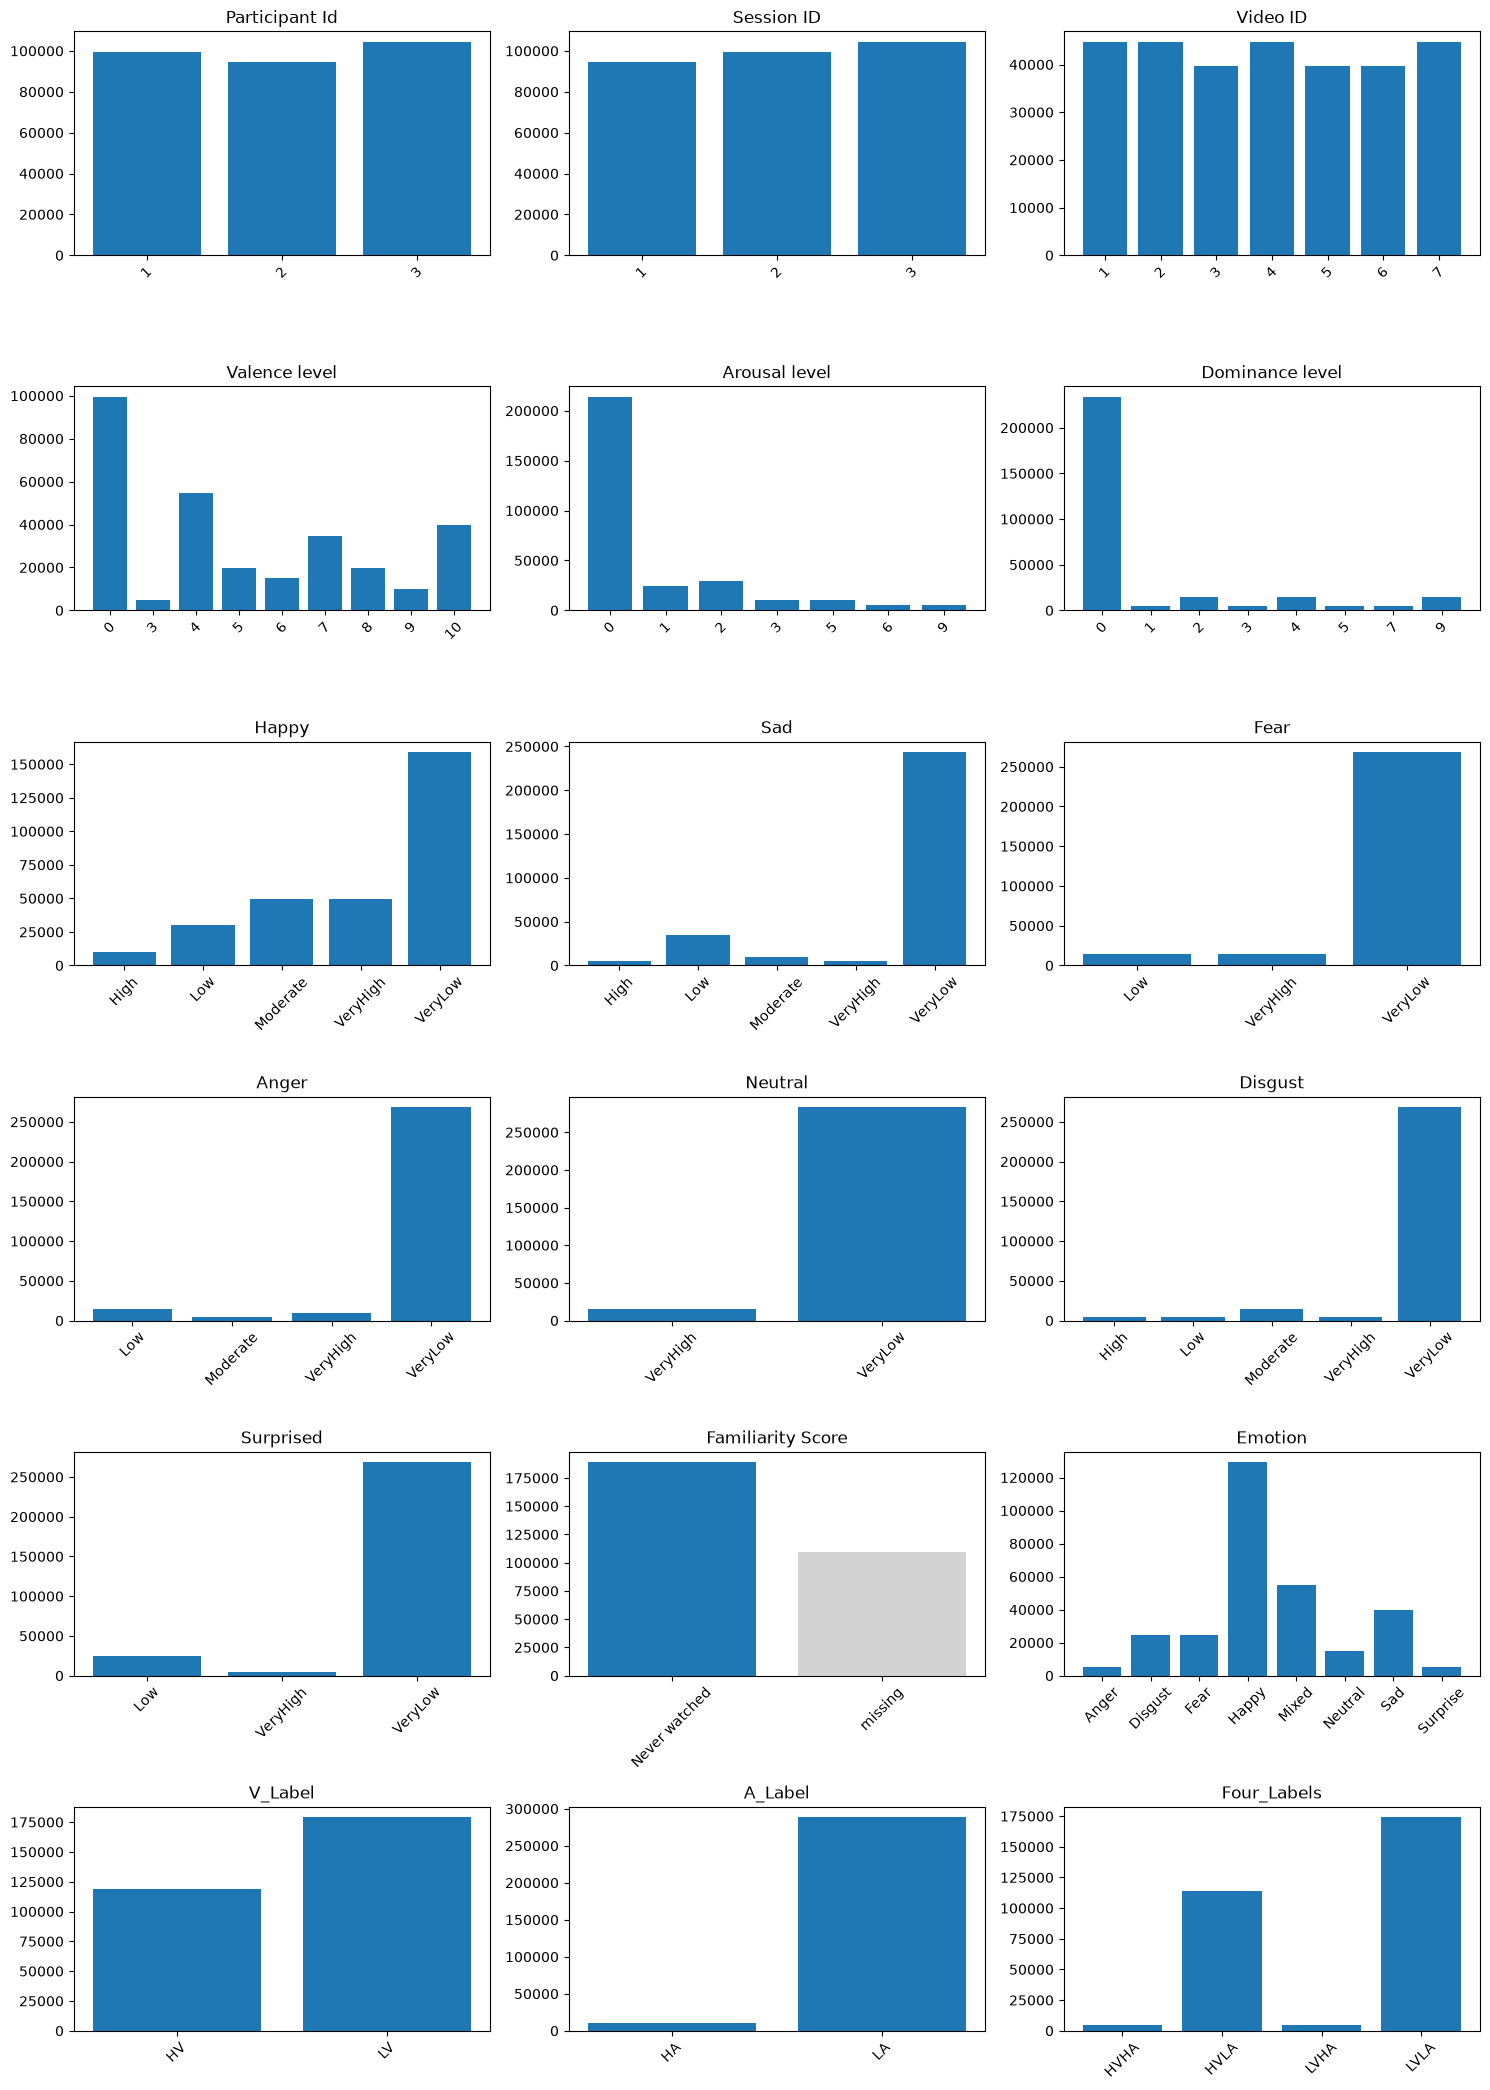

In [ ]:
### Visualise distribution ### 

import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

cols = [c for c in all_samples.columns if c != "window_sample"]
ncols = 3
nrows = math.ceil(len(cols) / ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 3.5 * nrows))
axes = np.atleast_1d(axes).ravel()

for ax, col in zip(axes, cols):
    counts = all_samples[col].value_counts(dropna=False)
    if pd.api.types.is_numeric_dtype(all_samples[col]):
        counts = counts.sort_index()                                  # 1, 2, ..., 10 rather than 1, 10, 2
    else:
        counts = counts.sort_index(key=lambda idx: idx.map(str))
    labels = [("missing" if pd.isna(v) else f"{v:g}" if isinstance(v, float) else str(v))
              for v in counts.index]
    colors = ["lightgrey" if l == "missing" else "C0" for l in labels]
    ax.bar(labels, counts.values, color=colors)
    ax.set_title(col)
    ax.tick_params(axis="x", labelrotation=45)

for ax in axes[len(cols):]:
    ax.set_visible(False)

fig.tight_layout()
plt.show()